<div style="background:#10273b;color:white;padding:30px;border-radius:12px">
<div style="color:#71d2c7;letter-spacing:2px;font-size:12px">FROM RANDOM WEIGHTS TO A REAL TEXT MODEL</div>
<h1 style="color:white;margin-top:10px">A Tiny GPT That Tells Corny Jokes</h1>
<p style="font-size:18px">Tokens → embeddings → causal attention → prediction → learning</p>
<p>English NLP introduction · Julia + Flux · local NVIDIA GPU training</p>
</div>

We will train a small **character language model from scratch** on public English question-and-answer jokes.
Every embedding, attention matrix, and output weight starts randomly. No pretrained model is loaded.

The result is a joke-completion experiment. It can learn spelling and question–punchline patterns;
that does not establish reliable humor, instruction following, or sustained multi-turn conversation.

**How to use this notebook:** run top to bottom to inspect the saved experiment. Set `RUN_TRAINING = true`
in Section 7 to train a fresh model yourself. Training has a 45-minute wall-clock budget inside the
training function, with one minute reserved for saving; package loading happens before that timer.
The original local run's measured duration is displayed below.

## 1 · The whole idea in one picture

A language model repeatedly asks: **given this prefix, which character should come next?**
In a larger LLM, tokens are usually subword pieces. Here, one character is one token, so we can
inspect every ID and prediction. The attention and learning principles remain the same.

In [1]:
using Pkg
ROOT = isfile(joinpath(pwd(), "Project.toml")) ? pwd() : normpath(joinpath(pwd(), ".."))
@assert isfile(joinpath(ROOT, "src", "JokesGPT.jl")) "Start in the repository root or notebooks/."
Pkg.activate(ROOT)
ENV["GKSwstype"] = "100"
using Flux, Random, LinearAlgebra, Statistics, Printf, Serialization, SHA, Plots
BLAS.set_num_threads(1)
if !isdefined(Main, :JokesGPT)
    include(joinpath(ROOT, "src", "JokesGPT.jl"))
end
using .JokesGPT
DATA = joinpath(ROOT, "reference", "datasets", "short_jokes")
OUT = joinpath(ROOT, "output", "jokes_gpt")
default(fontfamily="Helvetica", titlefontsize=12, guidefontsize=10, tickfontsize=9,
        legendfontsize=9, linewidth=2, framestyle=:box, gridalpha=0.15,
        size=(950,380), left_margin=9Plots.mm, right_margin=6Plots.mm,
        bottom_margin=10Plots.mm, top_margin=5Plots.mm)
println("Julia ", VERSION, " | Flux project activated")

  Activating project at `C:\Users\30945\Desktop\Yuxuan ZHAO\minnesota\Research\DeepLearningMacro`
Julia 1.12.4 | Flux project activated


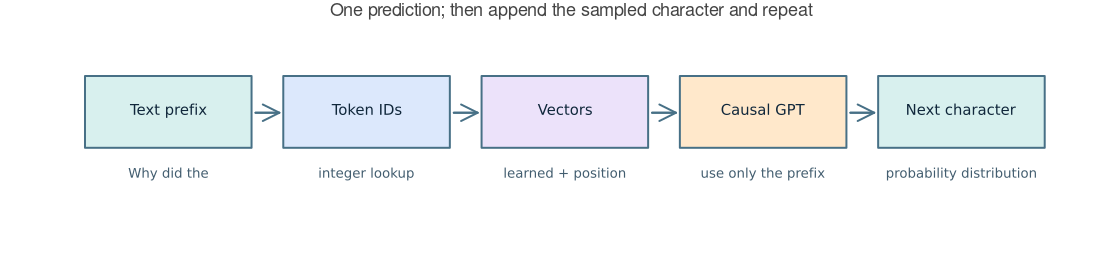

In [2]:
function flowchart(labels; title="", subtitles=fill("",length(labels)))
    n = length(labels)
    p = plot(xlims=(0,n), ylims=(0,1), axis=false, grid=false, legend=false,
             title=title, size=(1100,260), margin=5Plots.mm)
    colors = ["#d8f0ee", "#dce8fc", "#ece2fa", "#ffe8cb", "#d8f0ee"]
    for i in 1:n
        x = i-1
        plot!(p, Shape([x+0.04,x+0.88,x+0.88,x+0.04],[0.33,0.33,0.76,0.76]),
              fillcolor=colors[mod1(i,length(colors))], linecolor="#477086")
        annotate!(p, x+0.46, 0.56, text(labels[i],10,"#10273b"))
        annotate!(p, x+0.46, 0.18, text(subtitles[i],9,"#425d6f"))
        i < n && plot!(p,[x+0.9,x+1.02],[0.54,0.54],arrow=true,color="#477086")
    end
    p
end
flowchart(["Text prefix", "Token IDs", "Vectors", "Causal GPT", "Next character"];
    title="One prediction; then append the sampled character and repeat",
    subtitles=["Why did the", "integer lookup", "learned + position", "use only the prefix", "probability distribution"])

## 2 · A real corpus, with a deliberately narrow task

The source is [Abhinav Moudgil's Short Jokes dataset](https://github.com/amoudgl/short-jokes-dataset):
231,657 web-collected jokes. The preparation script selects short Q/A jokes whose subjects concern
ordinary animals, objects, food, or science, normalizes punctuation to ASCII, and applies a conservative
word/topic exclusion filter. **The filter is heuristic, not a semantic content guarantee.**

Exact normalized duplicates are removed. Equal normalized questions are grouped **before** the 90/5/5
train/validation/test split, so alternate punchlines for the same question stay together. Paraphrases
can still cross splits. Only then do we concatenate each split into a character stream.

The upstream README and GPL-2.0 repository license are preserved beside the CSV. The texts were scraped
from other sources; repository licensing should not be treated as a guarantee of rights in every joke.
See `reference/datasets/short_jokes/README.md` and `manifest.json` for provenance and exact hashes.

train       2675 jokes |  196778 characters
validation   145 jokes |   10398 characters
test         177 jokes |   12986 characters
Vocabulary: 96 characters = newline + 95 printable ASCII characters
Source SHA-256: e6337cc85c3a1110d1f666ff9a7bffd4e2f56014bf3168ae50b7ea480f469573


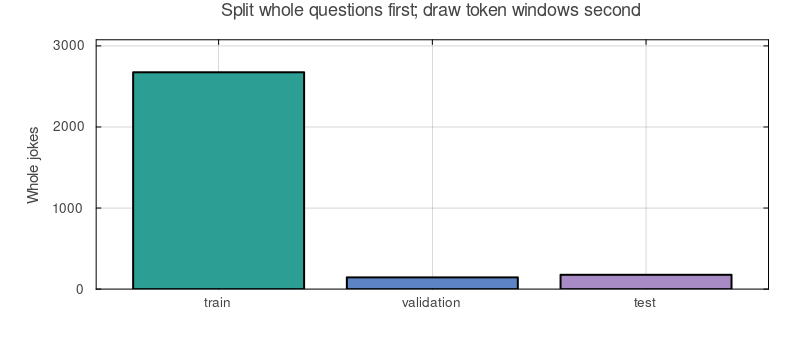

In [3]:
vocab, corpus = load_corpus(DATA)
V = length(vocab)
split_names = ["train", "validation", "test"]
joke_counts = [length(readlines(joinpath(DATA, name*".txt")))-1 for name in split_names]
for (name, n) in zip(split_names, joke_counts)
    @printf("%-10s %5d jokes | %7d characters\n", name, n, length(corpus[name]))
end
println("Vocabulary: ", V, " characters = newline + 95 printable ASCII characters")
println("Source SHA-256: ", bytes2hex(sha256(read(joinpath(DATA,"shortjokes.csv")))))
bar(split_names, joke_counts; fillcolor=["#2c9e94", "#5d85c6", "#a88ac5"], legend=false,
    ylabel="Whole jokes", title="Split whole questions first; draw token windows second",
    ylims=(0,1.15maximum(joke_counts)), size=(800,350))

## 3 · Tokens are IDs; embeddings are learned vectors

For this model, the text `Why?` becomes four character IDs. The numbers are just dictionary addresses:
ID 80 is not inherently more positive, larger, or more meaningful than ID 20.

An **embedding table** $E\in\mathbb R^{128\times96}$ assigns one 128-dimensional column to each ID.
We choose 128 as a model-size setting; training chooses the entries. A coordinate need not mean
"emotion", "finance", or "noun". Information can be distributed across many coordinates, and there is
no requirement that individual axes have human-readable meanings.

In [4]:
example = "Why?"
ids_example = encode(example, vocab)
println("Characters: ", collect(example))
println("Token IDs:  ", ids_example)
@assert decode(ids_example, vocab) == example
initial = load_checkpoint(joinpath(OUT,"initial.jls"))
println("Embedding table shape: ", size(initial.model.tokens.weight))
println("Vector for 'W', first 8 coordinates: ", round.(initial.model.tokens.weight[1:8,ids_example[1]];digits=3))

Characters: ['W', 'h', 'y', '?']
Token IDs:  [57, 74, 91, 33]
Embedding table shape: (128, 96)
Vector for 'W', first 8 coordinates: Float32[0.006, -0.018, 0.02, 0.012, 0.025, 0.002, 0.001, -0.002]


### How does an embedding learn? One update you can see

Use an intentionally tiny example: three possible output characters, one-dimensional embeddings,
and a fixed output head $[-1,0,1]^\top$. The input character's embedding starts at $e=0$.
Its logits are $[-e,0,e]$, so all three predictions initially have probability $1/3$.
Suppose the observed next character is the third one. Then

$$L(e)=-\log\frac{\exp(e)}{\exp(-e)+1+\exp(e)},\qquad L'(0)=-1.$$

Gradient descent with step size 0.2 changes $e$ to $0.2$. The third character becomes more likely.
In the actual GPT, the gradient travels through the output head, attention, and earlier layers to the
embedding table, and **all those trainable weights** are updated together.

Embedding: 0.000 → 0.200 | correct next-character probability: 0.333 → 0.402


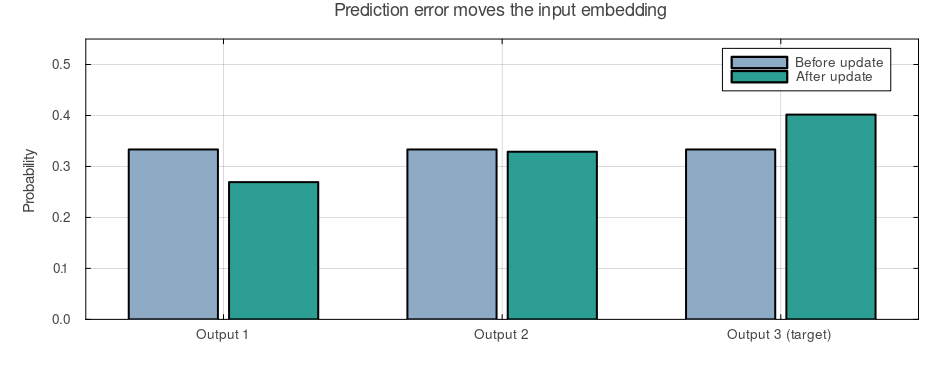

In [5]:
toy_embedding = Embedding(zeros(Float32,1,3))
toy_head = reshape(Float32[-1,0,1],3,1)
target = reshape(Float32[0,0,1],3,1)
probabilities(m) = vec(Flux.softmax(toy_head*m([1]);dims=1))
before_p = probabilities(toy_embedding)
toy_loss, toy_grad = Flux.withgradient(toy_embedding) do m
    Flux.logitcrossentropy(toy_head*m([1]), target)
end
toy_opt = Flux.setup(Flux.Descent(0.2f0),toy_embedding)
Flux.update!(toy_opt,toy_embedding,toy_grad[1])
after_p = probabilities(toy_embedding)
@printf("Embedding: 0.000 → %.3f | correct next-character probability: %.3f → %.3f\n",
    toy_embedding.weight[1,1],before_p[3],after_p[3])
@assert toy_embedding.weight[1,2:3] == [0f0,0f0] # untouched input rows/columns
x = collect(1:3)
p = bar(x .- 0.18,before_p;bar_width=0.32,label="Before update",color="#8eabc5")
bar!(p,x .+ 0.18,after_p;bar_width=0.32,label="After update",color="#2c9e94",
    xticks=(x,["Output 1","Output 2","Output 3 (target)"]),ylabel="Probability",
    ylims=(0,0.55),title="Prediction error moves the input embedding")

## 4 · Position and causal attention

Looking up a character vector alone says nothing about its position. We add a learned position vector:
$h_t=E[:,x_t]+P[:,t]$. Each layer then builds a different, **context-dependent** representation.
The table entry for a character is fixed within one forward pass; its hidden state depends on the prefix.

Think of a **query** as what the current position is looking for, a **key** as what another position
can match, and a **value** as the information it can contribute. These are learned vectors, not
human-written labels. Softmax converts scores to nonnegative weights that add up to one.

Attention gives each position a way to read earlier positions. For one head:

$$q_t=W_Qh_t,\quad k_s=W_Kh_s,\quad v_s=W_Vh_s,$$
$$a_{s,t}=\operatorname{softmax}_{s}\left(\frac{k_s^\top q_t}{\sqrt{d_{head}}}+M_{s,t}\right),
\qquad o_t=\sum_s a_{s,t}v_s.$$

Here rows are keys $s$ and columns are queries $t$. Set $M_{s,t}=-\infty$ when $s>t$:
a position cannot read its future answer. Several heads provide several learned views of the prefix.
Our four heads each have dimension $128/4=32$.

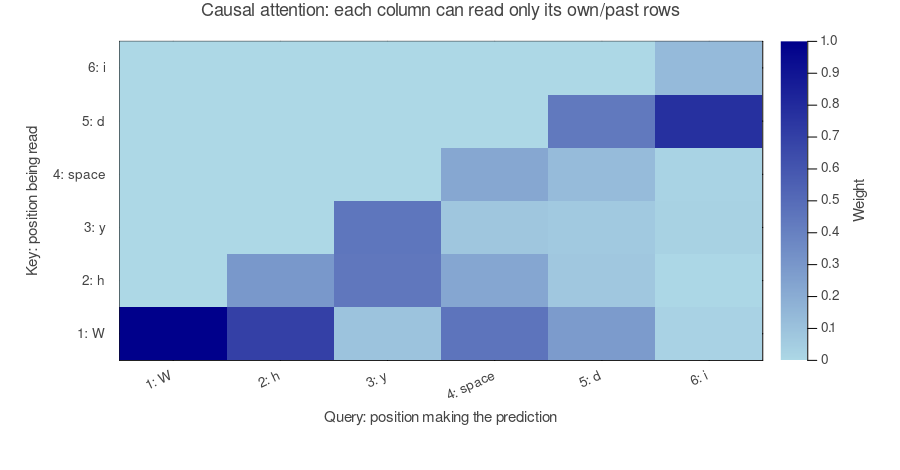

In [6]:
# A small illustrative attention calculation, not attention measured from the trained model.
rng_attn = MersenneTwister(4)
Q_demo, K_demo = randn(rng_attn,Float32,3,6),randn(rng_attn,Float32,3,6)
scores_demo = K_demo' * Q_demo / sqrt(3f0)
weights_demo = Flux.softmax(scores_demo .+ causal_mask(6);dims=1)
labels_demo = ["1: W","2: h","3: y","4: space","5: d","6: i"]
heatmap(labels_demo,labels_demo,weights_demo;clims=(0,1),color=:blues,
    xlabel="Query: position making the prediction",ylabel="Key: position being read",
    title="Causal attention: each column can read only its own/past rows",
    xrotation=25,size=(900,470),bottom_margin=16Plots.mm,colorbar_title="Weight")

### The GPT block, without a mystery box

This is a **decoder-only Transformer**, the architectural family used by GPT. Each block contains
causal multi-head attention, a small feed-forward network, layer normalization, and residual additions.
The linear output head maps the final hidden state to 96 logits; softmax turns them into probabilities.
Our model uses learned positions and untied input/output weights, with no dropout, to keep the example compact.

The **feed-forward network** is the same small nonlinear transformation applied at every position.
**Layer normalization** rescales a position's features to help stabilize learning. A **residual addition**
adds the old representation back, letting a block learn an adjustment instead of replacing everything.

An encoder–decoder translation model additionally encodes a source sentence and uses cross-attention
while decoding the target language. That architecture is useful for translation; it is not needed for
this single-stream next-character exercise. A "decoder" here outputs token probabilities; decoding
token IDs back to text is a separate, simple dictionary operation.

The readable implementation is in [`src/JokesGPT.jl`](../src/JokesGPT.jl). The core operations are:

```julia
H = token_embedding(ids) + position_embedding(positions)
for block in blocks
    H = H + causal_attention(layernorm1(H), mask)
    H = H + feedforward(layernorm2(H))
end
logits = output_head(final_layernorm(H))
```

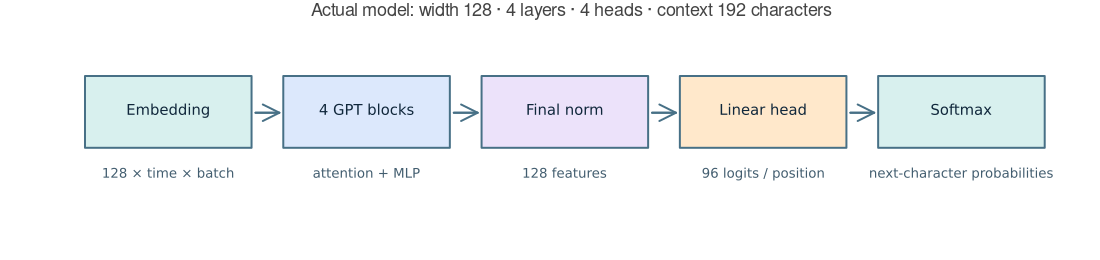

In [7]:
flowchart(["Embedding", "4 GPT blocks", "Final norm", "Linear head", "Softmax"];
    title="Actual model: width 128 · 4 layers · 4 heads · context 192 characters",
    subtitles=["128 × time × batch","attention + MLP","128 features","96 logits / position","next-character probabilities"])

## 5 · The training examples are shifted by one character

For `Why did`, the inputs are `Why di` and the targets are `hy did`. We can supervise every position
in parallel, because the causal mask prevents looking ahead. This is often called **teacher forcing**:
training uses the actual preceding characters, rather than the model's sampled mistakes.

We sample 192-character windows from the training stream. A newline separates whole jokes.
Some windows span that separator; this is ordinary stream language modeling, without chat role tokens.
The context length counts **characters**, not words, for this tokenizer.

$$L(\theta)=-\frac{1}{BT}\sum_{b,t}\log p_\theta(y_{t,b}\mid x_{1:t,b}).$$

This loss updates the embeddings **and** every attention/MLP/output weight. Backpropagation computes
which changes reduce the prediction error; Adam combines those gradients into parameter updates.

In [8]:
example_training = encode("Why did",vocab)
X_demo = reshape(example_training[1:end-1],:,1)
Y_demo = example_training[2:end]
println("Input:  ", repr(decode(vec(X_demo),vocab)))
println("Target: ", repr(decode(Y_demo,vocab)))
logits_demo = predict(initial.model,X_demo,causal_mask(size(X_demo,1)),collect(1:size(X_demo,1)))
println("Input shape (time, batch): ",size(X_demo))
println("Output shape (vocabulary, time, batch): ",size(logits_demo))
println("Trainable parameters: ",parameter_count(initial.model))

Input:  "Why di"
Target: "hy did"
Input shape (time, batch): (6, 1)
Output shape (vocabulary, time, batch): (96, 6, 1)
Trainable parameters: 842496


## 6 · What happens before any learning?

The initial checkpoint contains only seeded random weights. Its continuation should look like noise.
Generation appends one sampled character at a time, feeds the longer prefix back in, and stops at
newline or a length limit. Temperature controls how concentrated the probabilities are; top-k keeps
only the k highest-scoring characters. Neither setting can supply knowledge the model never learned.
Use printable ASCII English prompts: this deliberately small tokenizer does not support Chinese or emoji.

In [9]:
println(generate(initial.model,vocab;prompt="Why did the",seed=7,max_new=65))

Why did thevu3hfQoo8#,af|###oo%{f|"<hoy=||=#8%o88#|o6R|g/Qo/0oo|o<qg?8Lh6|o?


## 7 · Train from scratch on your GPU

The supplied checkpoint was produced by the same script below. Loading it makes the notebook quick
to explore. To do your own fresh run, change the switch to `true`; the trainer constructs a new
`TinyGPT` with random weights and replaces this experiment's local output files.

The trainer checks that all parameters really are CUDA arrays, clips gradient norm at 1, and uses
Adam with learning rate 0.0006. Every 500 updates it measures the same fixed training/validation windows.
It saves the best validation checkpoint and stops after six evaluations without improvement, at
16,000 updates, or near its wall-clock budget. It evaluates test windows only after checkpoint selection.

The initial CUDA compilation can take much longer than a later optimizer step. Timing includes that
first update; steady-state benchmark speed alone is not a promise about training quality or duration.

In [10]:
RUN_TRAINING = false
if RUN_TRAINING
    include(joinpath(ROOT,"experiments","train_jokes_gpt.jl"))
    train_jokes(;max_steps=16000,budget_seconds=45*60)
    initial = load_checkpoint(joinpath(OUT,"initial.jls"))
else
    println("Exploring the supplied local run. Set RUN_TRAINING = true for a fresh random initialization.")
end
trained = load_checkpoint(joinpath(OUT,"best.jls"))
model = trained.model # CPU copy: sampling and all following figures work without a GPU.
@assert all(p isa Array for p in Flux.trainables(model))
@assert trained.metadata["train_sha256"] == bytes2hex(sha256(read(joinpath(DATA,"train.txt"))))
@printf("Saved run: %.2f minutes | best step %d | last step %d\n",
    trained.metadata["elapsed_seconds"]/60,trained.metadata["best_step"],trained.metadata["last_step"])
println("Device used for training: ",trained.metadata["gpu"])
println("Stop reason: ",trained.metadata["stop_reason"])

Exploring the supplied local run. Set RUN_TRAINING = true for a fresh random initialization.
Saved run: 8.46 minutes | best step 2500 | last step 5500
Device used for training: NVIDIA GeForce RTX 5070
Stop reason: validation early stopping: six evaluations without improvement


## 8 · What did the model learn?

The training curve shows fit to seen text. Validation estimates prediction on held-out questions and
selects the checkpoint. A widening gap indicates overfitting. These are losses on fixed sampled
windows, not an exact full-corpus likelihood calculation.

We compare with a **character bigram** model, which predicts from only the immediately preceding
character. Its additive-smoothed counts are fit on training data only. Perplexity is `exp(loss)`;
for this experiment it is a character-level measure and cannot be compared directly with subword LLM scores.
The test split was not used to choose a checkpoint. None of these scores measures whether a joke is funny.

Best validation CE 1.2411 | test CE 1.2244 | test perplexity 3.40
Bigram test CE 2.3687 | perplexity 10.68


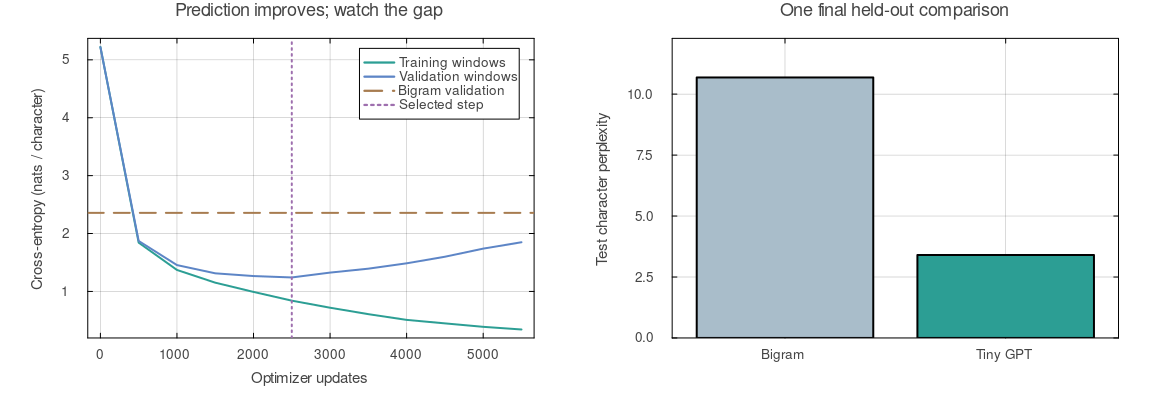

In [11]:
history = trained.history
steps = [h.step for h in history]
train_losses = [h.train_loss for h in history]
val_losses = [h.validation_loss for h in history]
baseline_val = trained.metadata["validation_bigram_loss"]
p1 = plot(steps,train_losses;label="Training windows",color="#2c9e94",
    xlabel="Optimizer updates",ylabel="Cross-entropy (nats / character)",title="Prediction improves; watch the gap")
plot!(p1,steps,val_losses;label="Validation windows",color="#5d85c6")
hline!(p1,[baseline_val];label="Bigram validation",linestyle=:dash,color="#a77c50")
vline!(p1,[trained.metadata["best_step"]];label="Selected step",linestyle=:dot,color="#9e6fae")
test_loss = trained.metadata["test_loss"]
bigram_test = trained.metadata["test_bigram_loss"]
p2 = bar(["Bigram","Tiny GPT"],exp.([bigram_test,test_loss]);fillcolor=["#a9bdca", "#2c9e94"],
    legend=false,ylabel="Test character perplexity",title="One final held-out comparison",
    ylims=(0,1.15maximum(exp.([bigram_test,test_loss]))))
@printf("Best validation CE %.4f | test CE %.4f | test perplexity %.2f\n",
    trained.metadata["best_validation_loss"],test_loss,exp(test_loss))
@printf("Bigram test CE %.4f | perplexity %.2f\n",bigram_test,exp(bigram_test))
plot(p1,p2;layout=(1,2),size=(1150,420),bottom_margin=13Plots.mm,left_margin=12Plots.mm)

### The embedding table actually moved

These are the first eight coordinates for a few character embeddings before and after training,
using the same color scale. The axes were not labeled with semantic features. They moved because
their gradients helped predict subsequent text, alongside changes to the rest of the network.
This visual demonstrates learning; it does not prove a specific linguistic meaning for any coordinate.

Full embedding-table change, Euclidean norm: 4.5848


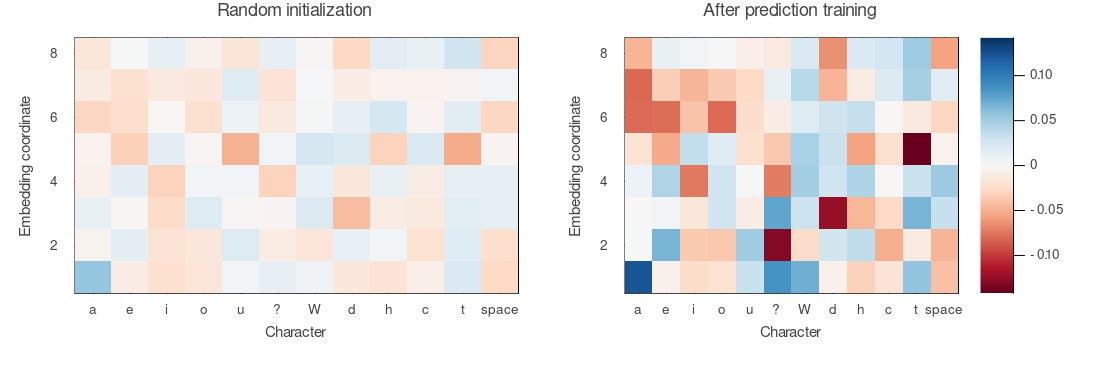

In [12]:
shown_chars = collect("aeiou?Wdhct ")
shown_ids = [findfirst(==(c),vocab) for c in shown_chars]
E0 = initial.model.tokens.weight[1:8,shown_ids]
E1 = model.tokens.weight[1:8,shown_ids]
extent = max(maximum(abs,E0),maximum(abs,E1))
labels_chars = [c == ' ' ? "space" : string(c) for c in shown_chars]
p0 = heatmap(labels_chars,1:8,E0;clims=(-extent,extent),color=:RdBu,
    xlabel="Character",ylabel="Embedding coordinate",title="Random initialization",colorbar=false)
p1 = heatmap(labels_chars,1:8,E1;clims=(-extent,extent),color=:RdBu,
    xlabel="Character",ylabel="Embedding coordinate",title="After prediction training")
@printf("Full embedding-table change, Euclidean norm: %.4f\n",norm(model.tokens.weight-initial.model.tokens.weight))
plot(p0,p1;layout=(1,2),size=(1100,370),bottom_margin=12Plots.mm)

## 9 · Generate, then judge the actual text

These are fixed-seed samples, without manual rewriting or searching over seeds for a good answer.
You may see familiar training jokes, plausible new combinations, broken spelling, or a sentence that
looks like a joke but has no working punchline. That mixture is useful evidence about a tiny model.
We compare temperatures 0.5 and 0.8 using the same prompts and seeds. Lower temperature concentrates
the distribution; it can also make repetition or copying more likely. Neither setting guarantees coherence.

In [13]:
prompts = ["Why did the computer", "What do you call a", "Why did the chicken"]
generated_samples = String[]
for temperature in (0.5,0.8)
    println("Temperature = ",temperature)
    for (i,prompt) in enumerate(prompts)
        sample = generate(model,vocab;prompt,seed=7+i,temperature,top_k=30,max_new=150)
        push!(generated_samples,sample)
        println(i,". ",sample)
    end
end

Temperature = 0.5
1. Why did the computer spider the runes sage afraid that the banana? A: It was goes too standing the piance of bane.
2. What do you call a cow that just gave birth? A subwoofer.
3. Why did the chicken cross the road? Because it was two-tired.
Temperature = 0.8
1. Why did the computer gay to the piance? The pottal personal
2. What do you call a fish with no eyes? A cheete cheese cheese cheesy take basky-dong.
3. Why did the chicken cross the road? To get to the slelly down mes ? A coster the work.


### Did it simply copy a joke?

An exact-match check is a limited diagnostic: finding a match demonstrates copying, while failing
to find one does not establish originality. Minor edits and memorized fragments can evade this test.
Our small corpus and relatively large parameter count make memorization an expected concern.

In [14]:
normalize_match(s) = replace(lowercase(s),r"[^a-z0-9]" => "")
training_fingerprints = Set(normalize_match(s) for s in readlines(joinpath(DATA,"train.txt")) if !isempty(s))
for (i,sample) in enumerate(generated_samples)
    println("Sample ",i," exact normalized training match: ",normalize_match(sample) in training_fingerprints)
end

Sample 1 exact normalized training match: false
Sample 2 exact normalized training match: false
Sample 3 exact normalized training match: false
Sample 4 exact normalized training match: false
Sample 5 exact normalized training match: false
Sample 6 exact normalized training match: false


## 10 · A small check that attention cannot cheat

Change future input characters while holding the first five positions fixed. The first five predictions
must stay the same. Predicting a prefix on its own should also agree with the corresponding positions
in the longer sequence, up to floating-point rounding.

In [15]:
probe = reshape(encode("Why did the cat?",vocab),:,1)
T_probe = size(probe,1)
L_original = predict(model,probe,causal_mask(T_probe),collect(1:T_probe))
changed = copy(probe)
changed[6:end,1] .= encode("Z",vocab)[1]
L_changed = predict(model,changed,causal_mask(T_probe),collect(1:T_probe))
future_effect = maximum(abs.(L_original[:,1:5,:]-L_changed[:,1:5,:]))
prefix_logits = predict(model,probe[1:5,:],causal_mask(5),collect(1:5))
prefix_difference = maximum(abs.(L_original[:,1:5,:]-prefix_logits))
reference = deserialize(joinpath(OUT,"verification_probe.jls"))
reload_difference = maximum(abs.(L_original-reference.logits))
@printf("Effect of changing future characters: %.3g\n",future_effect)
@printf("Full-sequence vs separate-prefix difference: %.3g\n",prefix_difference)
@printf("Saved checkpoint reference difference: %.3g\n",reload_difference)
@assert future_effect < 1f-5
@assert prefix_difference < 1f-4
@assert reload_difference < 1f-5
@assert norm(model.tokens.weight-initial.model.tokens.weight) > 0
println("Causality and learned-embedding checks passed.")

Effect of changing future characters: 0
Full-sequence vs separate-prefix difference: 4.89e-06
Saved checkpoint reference difference: 0
Causality and learned-embedding checks passed.


## 11 · What this experiment teaches, and what comes next

| Object | What we chose | What training learned |
|---|---|---|
| Tokenizer | Fixed 96-character alphabet | Nothing: this lookup is deterministic |
| Embeddings | Width 128, random initialization | Useful distributed character representations |
| Positions | Learned table with 192 slots | Position-dependent adjustments |
| Attention | 4 layers, 4 heads; causal mask | Which available context to read |
| Output head | 96 possible next characters | Scores used for next-character prediction |
| Objective | Cross-entropy on the next character | Parameters that reduce that prediction error |

To experiment, change **one thing at a time**: temperature, a prefix, then model width or corpus size.
For a clean model-size comparison, keep the dataset split and evaluation windows fixed. If repeatedly
tuning the experiment, leave the test set untouched and use a new final test evaluation only when ready.

A general English assistant would need much broader data, a larger context and model, and training
that teaches conversational roles and instruction following. This notebook isolates the first building
block: learning a probability distribution over text **from random weights**.

**Reproduce the local experiment** from the repository root:

```text
C:/Anaconda/python.exe experiments/prepare_jokes_data.py
julia --startup-file=no --project=. experiments/train_jokes_gpt.jl
```

The CSV is already downloaded. `prepare_jokes_data.py` uses Python standard libraries only; all model
code and training use the existing Julia project. The Julia `Serialization` checkpoint is intended for
this recorded project environment; define `JokesGPT` before loading it. The checkpoint contains CPU
weights, configuration, vocabulary, history, and data hashes. It does not contain optimizer state for
exactly resuming an interrupted run; rerunning training starts fresh.

Sources: [Short Jokes corpus and construction](https://github.com/amoudgl/short-jokes-dataset),
[Attention Is All You Need](https://arxiv.org/abs/1706.03762),
[Flux training documentation](https://fluxml.ai/Flux.jl/stable/guide/training/training/).